---
<br>

![LogoTEC](logo.png)

# IC4302 - Bases de Datos II  
## Proyecto #3

### *Tema: extraer, transformar y cargar datos con SparkSQL*

---

**Estudiantes:**  
- Angie Esquivel López
- Diego Zamora Bustos
- Jose Adrián Herrera Salas
- Sebastian Quesada Córdoba

**Profesor:** Alberto Shum Chan  

**Fecha de entrega:** 18/06/2025

## Descripción general del sistema

Este proyecto tiene como objetivo aplicar el proceso de extracción, transformación y carga de datos (ETL). Para ello, el profesor proporcionó dos conjuntos de datos correspondientes al año **2011**: uno del Instituto Nacional de Estadística y Censos `(INEC)` y otro del Organismo de Investigación Judicial `(OIJ)`. En el desarrollo del proyecto se hace uso de diversas bibliotecas de `PySpark`, las cuales facilitan el procesamiento, limpieza y análisis de los datos de manera eficiente en un entorno distribuido. Una vez que los datos han sido transformados y limpiados, se cargan en una base de datos `PostgreSQL`. A partir de estos datos almacenados, se generan visualizaciones que permiten analizar diferentes patrones y relaciones, facilitando una mejor comprensión de la información.

## Instalación y configuración de herramientas
**Primer paso**: 

Instalar **"PySpark"** para trabajar con `Apache Spark` desde `Python`.

<img src="PASO4.png" alt="Instalación de PySpark" width="700">
Usando el comando :

```bash
pip install pyspark

**Segundo paso:** 

Se deben de instalar las siguientes bibliotecas:
1. **pandas**
- Sirve para leer, escribir y manipular datos tabulares (como los de Excel, CSV o bases de datos).
- Proporciona estructuras de datos como `DataFrame` para trabajar con filas y columnas fácilmente.
2. **SQLAlchemy**
- Es un ORM (Object Relational Mapper) para conectarse a `PostgreSQL`.

<img src="PASO6.png" alt="Instalación de pandas y SQLAlchemy" width="700">
Usando el comando: 

```bash
pip install sqlalchemy pandas

**Tercer paso:**  

Se debe de descargar la biblioteca llamada **"pandas openpyxl"**, que permite a `pandas` leer y escribir archivos `.xlsx` (Excel moderno).  
<img src="PASO7.png" alt="Instalación de pandas openpyxl" width="550">

Usando el comando:  
```bash
pip install pandas openpyxl


**Cuarto paso**:

Se instala la biblioteca llamada **"xlrd"**, este que permite a `Python` leer archivos de `Excel` en formato .xls, que es el formato antiguo.  
<img src="PASO8.png" alt="Instalación de xlrd" width="700">

Usando el comando:

```bash
pip3 install xlrd


**Quinto paso**:

Se instala la biblioteca **"matplotlib"**, esta es una biblioteca para crear visualizaciones estáticas, animadas e interactivas en Python. 
Se instaló usando el siguiente comando:
```bash 
!pip install matplotlib

**Inicializar Jupyter Notebook:**


<img src="PASO2.png" alt="Inicializar Jupyter Notebook en Terminal" width="700">

Al ejecutar el siguiente comando:
```bash
jupyter notebook 
```
Lo que redirige a la siguiente ventana:

<img src="PASO3.png" alt="Inicializar Jupyter Notebook en Terminal" width="700">

In [25]:
# Bibliotecas requeridas para el proyecto
import os
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
import matplotlib.pyplot as plt

In [26]:
# Inicializar una sesión de Spark y datos para guardar los datos limpios en PostgreSQL
# Las credenciales y la ruta del driver JDBC se leen de variables de entorno (nunca en el código)
POSTGRESQL_URL = os.environ.get("POSTGRESQL_URL", "jdbc:postgresql://localhost:5432/Proyecto3")
POSTGRESQL_USER = os.environ.get("POSTGRESQL_USER", "postgres")
POSTGRESQL_PASSWORD = os.environ["POSTGRESQL_PASSWORD"]
JDBC_DRIVER_JAR = os.environ.get("JDBC_DRIVER_JAR", "postgresql-42.7.3.jar")

def create_spark_session():
    spark = SparkSession \
        .builder \
        .appName("Basic JDBC pipeline") \
        .config("spark.driver.extraClassPath", JDBC_DRIVER_JAR) \
        .config("spark.executor.extraClassPath", JDBC_DRIVER_JAR) \
        .getOrCreate()
    return spark

spark = create_spark_session()

## Descripción de las funciones
### Función que elimine los espacios en blanco de la columna distrito para usarse en ambos conjuntos de datos:
Primero se deben de leer los archivos `.xls` y `.xlsx` para poder leer estos datos, para esto se usa `pandas` junto con `xlrd` para el primer conjunto, y `openpyxl` para el segundo. Esto se debe a que se tratan de dos versiones de `Excel` distintas.

In [27]:
pdDfINEC = pd.read_excel("reempleocenso2011-22.xls_2.xls", engine="xlrd", skiprows=5)
pdDfOIJ = pd.read_excel("Estadisticas.xlsx", engine="openpyxl")

Luego se deben de crear los `Data Frame` con los dos conjuntos de datos para empezar a transformar los datos:

In [28]:
DfINEC = spark.createDataFrame(pdDfINEC)
DfOIJ = spark.createDataFrame(pdDfOIJ)

Para el conjunto de ***datos del OIJ***:

In [29]:
def limpiar_espacios_col(df, col_name):
    return df.withColumn(col_name, regexp_replace(col(col_name), " ", ""))

DfOIJ = limpiar_espacios_col(DfOIJ, "distrito")

Para el conjunto de ***datos del INEC:***

In [30]:
DfINEC = limpiar_espacios_col(DfINEC, "Provincia, cantón y distrito")

### Documentación:
- **Descripción general:**  
Este script toma el `DataFrame` al que se le va a tranformar sus registros y el nombre de la columna que se desea eliminar los espacios.

- **Descripción de los parámetros:**  
Este parámetro representa el `DataFrame` de entrada y la columna sobre el que se va a aplicar la transformación.

- **Descripción de la salida:**  
Devuelve un nuevo DataFrame, pero con la columna distrito modificada para remover todos los espacios contenidos en la columna "distrito" o "provincia, cantón y distrito" para el conjunto de datos del **INEC**.

- **Descripción de bloques relevantes:**  
Lo más relevante del script anterior es la parte de `regexp_replace(..., " ", "")` que reemplaza cada espacio (" ") por una cadena vacía (""), es decir, los elimina.


### Función que convierta a minúsculas el contenido de la columna distrito para usarse en ambos conjuntos de datos:

- #### **Conjunto de datos del OIJ**:

In [31]:
def convertir_minusculas(df, col_nombre):
    return df.withColumn(col_nombre, lower(col(col_nombre)))

DfOIJ = convertir_minusculas(DfOIJ,"distrito")

- #### **Conjunto de datos del INEC:**

In [32]:
DfINEC = convertir_minusculas(DfINEC, "Provincia, cantón y distrito")
"Se elimina las filas NAN"
DfINEC = DfINEC.dropna(how="all")

### Documentación:
- **Descripción general:**  
Este script convierte todos los registros de la columna `distrito` o `Provincia, cantón y distrito` dependiendo del conjunto de datos con el que se esté trabajando a minúsculas.

- **Descripción de los parámetros:**  
Como la función anterior, el parámetro representa el DataFrame de entrada y la columna sobre la que se va a aplicar la transformación.

- **Descripción de la salida:**  
Devuelve un nuevo DataFrame, pero con la columna distrito modificada con los registros en minúscula contenidos en la columna `distrito` o `Provincia, cantón y distrito`.

- **Descripción de bloques relevantes:**  
La parte relevante del script anterior es `lower(...)` esta convierte el contenido de la columna a letras minúsculas.

### Función que devuelva la lista de distritos del conjunto de datos del OIJ que no coinciden con ningún distrito del conjunto de datos del INEC:
Para esta función se debe usar la función `join` de los `DataFrames`, haciendo uso de la opción `left_anti`, que en `pyspark.sql` cumple el rol de un `left join` pero devolviendo únicamente los registros del primer conjunto que **no tienen coincidencias** en el segundo. En este caso, el conjunto **A** representa los datos del `OIJ`, mientras que el conjunto **B** representa los datos del `INEC`. Esta relación se visualiza mejor en la siguiente imagen: 

<p align="center"> <img src="leftJoin.png" alt="leftJoin" /> </p> <p align="center" style="font-size: smaller;"> Fuente: https://medium.com/@adilsaid64/understanding-sql-joins-a-quick-guide-with-examples-b0985419ea85 </p>

In [33]:
distritos_no_encontrados = DfOIJ.join(
    DfINEC,
    DfOIJ["distrito"] == DfINEC["Provincia, cantón y distrito"],
    how="left_anti"
)
resultados = distritos_no_encontrados.select("distrito").distinct().collect()
# Imprimir cada distrito
for row in resultados:
    print(row["distrito"])


rioazul
para
colon
guapiles
guacimo
puraba
cajon
lalegua
granja
canasdulces
desconocido
rionuevo
sannicolas
tarcoles
alegria
patarra
leonxiii
cortes
sanjoaquin
sanjosedelamonta?a
sanchez
dulcenombredejesus
general
santalucia
santotomas
horquetas
ceiba
guacima
sarchisur
aserri
guaycara
fortuna
sanjeronimo
cobano
mataplatano
angeles
jaco
losangeles
riojimenez
rioblanco
tapezco
jesus
batan
paraiso
riocuarto
cachi
merecedes
llanosdesantalucia
canas
limon
sanfranciscodedosrios
cairo
asuncion
jimenez
diria
sarchinorte
tresrios
sanramon
turrucares
sanjose
sanjose(pizote)
macacoma
concepcion
espiritusanto
sansebastian
monterry
escazu
bahiaballena
ipis
juanvinas
sancristobal
duacari
riosegundo
santabarbara
bolivar
canonegro
belen
santamaria
palmera
pavon
baru
volcan
dosrios
mastate
tilaran
penasblancas
samara
bolson
libano
sanandres
belendenosarita
paramo
curubande
cirrisur
mansion
tigra
jesusmaria
changuena
jardin
rodriguez
elchirripo


### Documentación:

- **Descripción general:**  
  El script devuelve una lista que contiene los registros que se encuentran en el conjunto de datos del `OIJ` y no se encuentran en el conjunto del `INEC`.

- **Descripción de los parámetros:**  
  No posee parámetros, ya que es un procedimiento, no una función como tal.

- **Descripción de la salida:**  
  Una lista de los distritos que se encuentran en el `OIJ` y no en el `INEC`.

- **Descripción de bloques relevantes:**  
  Un bloque relevante en este script es el uso de `left_anti`, que permite obtener los datos que están presentes en el conjunto del `OIJ` pero no en el conjunto del `INEC`.  
  Además, se le aplica `.distinct()` para eliminar duplicados.


### Función que devuelva la cantidad de registros en el conjunto de datos del OIJ que no coinciden con ningún distrito del conjunto de datos del INEC: 

In [34]:
cantidad = distritos_no_encontrados.select("distrito").count()
print(f"Cantidad de distritos del OIJ que no están en el INEC: {cantidad}")

Cantidad de distritos del OIJ que no están en el INEC: 11526


Para esta función, el equipo se percató que se usa la misma lógica de la función anterior, por lo que solo hubo unos cambios mínimos para llegar al resultado esperado. Después de realizar el `select("distrito")` no se agregó el `.distict()` ya que se ocupa saber la cantidad total de registros que no se encuentran en el `INEC`, luego se añadió un `.count()` para poder contarlos.
### Documentación:

- **Descripción general:**  
  El script devuelve la cantidad de registros que se encuentran en el conjunto de datos del `OIJ` y no se encuentran en el conjunto del `INEC`.

- **Descripción de los parámetros:**  
  No posee parámetros, ya que es un procedimiento, no una función como tal.

- **Descripción de la salida:**  
  La cantidad de los distritos que se encuentran en el `OIJ` y no en el `INEC`.

- **Descripción de bloques relevantes:**  
  Un bloque relevante en este script es el uso de `left_anti`, que permite obtener los datos que están presentes en el conjunto del `OIJ` pero no en el conjunto del `INEC`. Luego se le aplica un `.count()` para poder contar los registros.


### Utilizando SparkSQL, edite los nombres de los distritos del INEC para que coincidan con algunos de los del OIJ:
Para esta función se visualizó el resultado de la función que devuelve la lista completa de registros del `OIJ` que no coinciden con algunos de los del `INEC`, además se realizó la misma lógica pero ahora con el objetivo de saber los registros del `INEC` que no están en los datos del `OIJ`. Al analizar ambas listas, el grupo se percató que muchos de los registros tenían como única diferencia el uso o no de tildes o la existencia de `ñ`. Por lo que se realizó una función que eliminara las tildes y las eñes, con el objetivo que algunos de los registros del conjunto de datos del `INEC` coincidan con el `OIJ`.

In [35]:
def quitar_tildes_y_ene(df):
    return df.withColumn(
        "Provincia, cantón y distrito",
        translate(
            col("Provincia, cantón y distrito"),
            "áéíóúñ",
            "aeioun"
        )
    )

DfINEC = quitar_tildes_y_ene(DfINEC)

Antes proseguir con la **documentación** de la función, se ejecutó de nuevo la función que devuelve la cantidad de los registros del `OIJ` que no coinciden con el `INEC` ahora con los datos actualizados, para visualizar la diferencia.

In [36]:
distritos_no_encontrados = DfOIJ.join(
    DfINEC,
    DfOIJ["distrito"] == DfINEC["Provincia, cantón y distrito"],
    how="left_anti"
)
cantidad = distritos_no_encontrados.select("distrito").distinct().count()
print(f"Cantidad de distritos del OIJ que no están en el INEC: {cantidad}")

Cantidad de distritos del OIJ que no están en el INEC: 23


### Documentación

- **Descripción general:**

  Este script en PySpark limpia la columna `"Provincia, cantón y distrito"` del `DataFrame`, eliminando tildes y la letra `ñ`, y guarda el resultado en el mismo `DataFrame`.

- **Parámetros:**

  Representa el `DataFrame` de entrada sobre el que se va a aplicar la transformación, en este caso al conjunto de datos del `INEC`.

- **Salida:**

  `DataFrame` sin tildes ni `ñ` en la columna `Provincia, cantón y distrito`.

- **Bloques clave:**

  Se usa `translate()` para reemplazar tildes (`áéíóúñ` → `aeioun`).



## Almacenacimiento de datos transformados en PostgreSQL:

In [37]:
def write_spark_df_to_db(spark_df, table_name):
    spark_df \
        .write \
        .format("jdbc") \
        .mode('overwrite') \
        .option("url", POSTGRESQL_URL) \
        .option("user", POSTGRESQL_USER) \
        .option("password", POSTGRESQL_PASSWORD) \
        .option("dbtable", table_name) \
        .save()

write_spark_df_to_db(DfINEC.select(
    "Provincia, cantón y distrito", 
    "Población de 15 años y más",
    "Tasa neta de participación",
    "Tasa de ocupación",
    "Tasa de desempleo abierto",
    "Porcentaje de población económicamente inactiva",
    "Relación de dependencia económica",
    "Porcentaje de población ocupada  ",
    "Unnamed: 9",
    "Unnamed: 10"
), "DatosINEC")

In [38]:
write_spark_df_to_db(DfOIJ.select(
    "Delito", 
    "SubDelito",
    "Fecha",
    "Hora",
    "Victima",
    "SubVictima",
    "Edad",
    "Sexo",
    "Nacionalidad",
    "Provincia",
    "Canton",
    "distrito"
), "DatosOIJ")

Luego se verifica si en realidad se almacenó en la base de datos `PostgreSQL`:
<img src="PostgreSQL-OIJ.png" alt="Verificación de almacenamiento de datos" width="700">

## Visualizaciones:
-  ### Visualización 1:
Compare la cantidad de delitos y la tasa de ocupación para los 10 distritos con más delitos en el país.


In [39]:
visualizacion = """
SELECT 
    distritos_top.distrito AS "Distrito",
    distritos_top.cantidad_delitos,
    inec_agregado.tasa_ocupación
FROM (
    SELECT 
        distrito, 
        COUNT(*) AS cantidad_delitos
    FROM 
        DatosOIJ
    GROUP BY 
        distrito 
    ORDER BY 
        cantidad_delitos DESC
    LIMIT 10
) AS distritos_top
LEFT JOIN (
    SELECT 
        "Provincia, cantón y distrito" AS distrito, 
        AVG("Tasa de ocupación") AS tasa_ocupación
    FROM 
        DatosINEC
    GROUP BY 
        "Provincia, cantón y distrito"
) AS inec_agregado
ON distritos_top.distrito = inec_agregado.distrito 
ORDER BY distritos_top.cantidad_delitos DESC
"""

Tabla1 = spark.read \
    .format("jdbc") \
    .option("url", POSTGRESQL_URL) \
    .option("dbtable", f"({visualizacion}) AS subquery") \
    .option("user", POSTGRESQL_USER) \
    .option("password", POSTGRESQL_PASSWORD) \
    .load()

Tabla1.show()

+---------+----------------+------------------+
| Distrito|cantidad_delitos|    tasa_ocupación|
+---------+----------------+------------------+
|sanrafael|            1262| 52.84867401850269|
|    limon|            1176|47.598711689315145|
|  liberia|            1108|  49.8163745881092|
| hospital|            1079|53.928192898781134|
| catedral|            1073| 57.02848631539751|
| sanpedro|            1011|  49.9507730448892|
| alajuela|             990|52.835248830051796|
|   quepos|             857| 54.00286162022212|
|   merced|             850|  56.9963749352667|
|     jaco|             792| 60.02415458937198|
+---------+----------------+------------------+



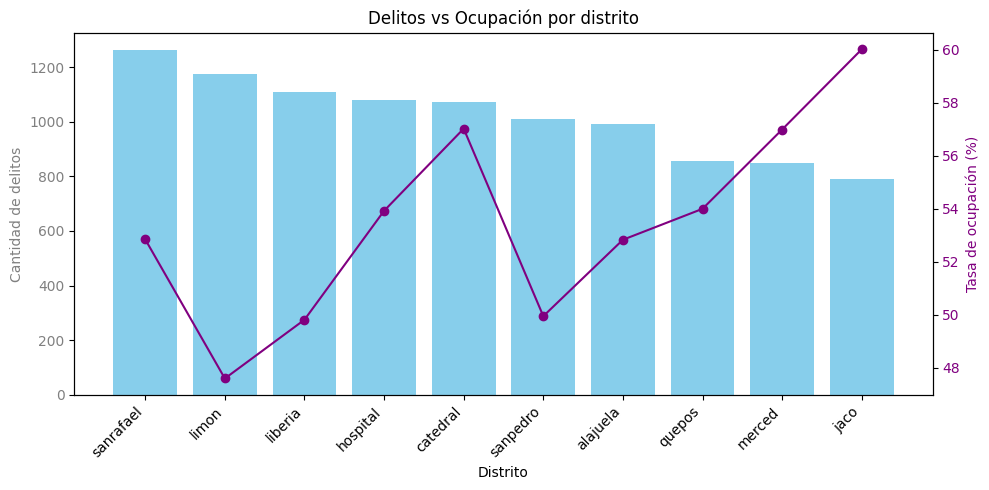

In [40]:
# Convertir a pandas
pandas_df = Tabla1.toPandas()

plt.figure(figsize=(10, 5))

plt.bar(pandas_df["Distrito"], pandas_df["cantidad_delitos"], 
        color='skyblue', label='Delitos')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Distrito')

# Eje Y izquierdo (delitos)
plt.ylabel('Cantidad de delitos', color='gray')
plt.tick_params(axis='y', labelcolor='gray')

# Gráfico de línea (ocupación) - eje Y derecho
ax2 = plt.twinx()
ax2.plot(pandas_df["Distrito"], pandas_df["tasa_ocupación"], 
         color='purple', marker='o', label='Ocupación (%)')
ax2.set_ylabel('Tasa de ocupación (%)', color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

plt.title('Delitos vs Ocupación por distrito')

plt.tight_layout()
plt.show()

#### Descripción:
Para esta visualización, se utilizó una consulta SQL para obtener los diez distritos con más delitos registrados en los datos del `OIJ` y se les unió la tasa de ocupación promedio desde los datos del `INEC`. El resultado se cargó desde `PostgreSQL` usando `PySpark` y luego se convirtió a un `DataFrame` de `Pandas`. Con `Matplotlib`, se creó un gráfico combinado: un gráfico de barras que muestra la cantidad de delitos por distrito y, sobre este, una línea con marcadores que representa la tasa de ocupación. Se usaron dos ejes Y para facilitar la comparación entre ambas variables. Esta visualización permite observar posibles relaciones entre empleo y criminalidad en los distritos con mayor cantidad de delitos.

- ### Visualización 2:
Gráfica de la cantidad de delitos por día de la semana para el distrito con más delitos.

In [41]:
visualizacion = """
WITH distrito_top AS (
    SELECT distrito
    FROM DatosOIJ
    GROUP BY distrito
    ORDER BY COUNT(*) DESC
    LIMIT 1
)
SELECT 
    EXTRACT(DOW FROM "Fecha") AS dia_semana,
    COUNT(*) AS delitos
FROM DatosOIJ
WHERE distrito = (SELECT distrito FROM distrito_top)
GROUP BY dia_semana
ORDER BY dia_semana
"""

Tabla2 = spark.read \
    .format("jdbc") \
    .option("url", POSTGRESQL_URL) \
    .option("dbtable", f"({visualizacion}) AS subquery") \
    .option("user", POSTGRESQL_USER) \
    .option("password", POSTGRESQL_PASSWORD) \
    .load()

Tabla2.show()

+--------------------+-------+
|          dia_semana|delitos|
+--------------------+-------+
|0.000000000000000000|    125|
|1.000000000000000000|    179|
|2.000000000000000000|    182|
|3.000000000000000000|    203|
|4.000000000000000000|    206|
|5.000000000000000000|    202|
|6.000000000000000000|    165|
+--------------------+-------+



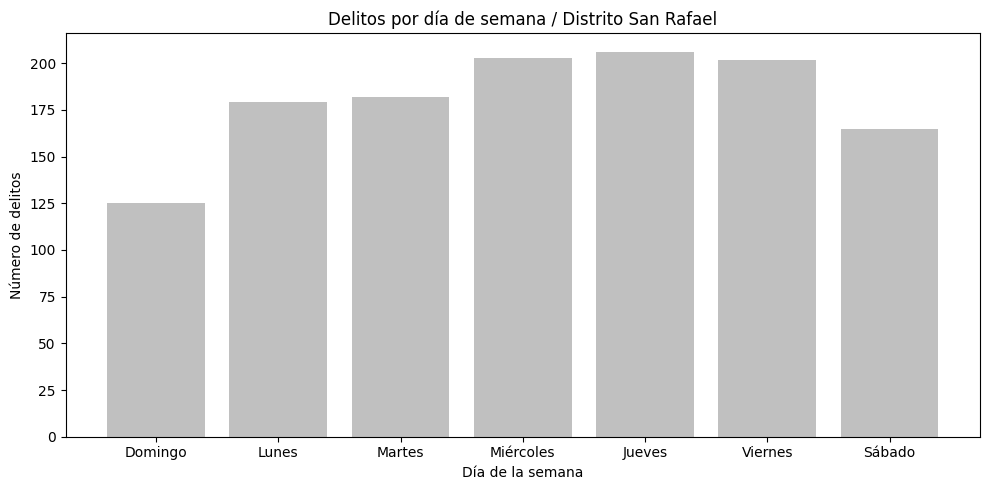

In [42]:
df_pd = Tabla2.toPandas()

# Mapeo de días
dias_semana = {
    0: "Domingo",
    1: "Lunes",
    2: "Martes",
    3: "Miércoles", 
    4: "Jueves",
    5: "Viernes",
    6: "Sábado"
}
df_pd["dia"] = df_pd["dia_semana"].map(dias_semana)

# Ordenar por día de semana
df_pd = df_pd.sort_values("dia_semana")

plt.figure(figsize=(10, 5))
plt.bar(df_pd["dia"], df_pd["delitos"], color="#C0C0C0")

# Elementos básicos
plt.title("Delitos por día de semana / Distrito San Rafael")
plt.xlabel("Día de la semana")
plt.ylabel("Número de delitos")

plt.tight_layout()
plt.show()

#### Descripción:
En esta visualización se analiza la distribución de delitos a lo largo de los días de la semana en el distrito con mayor cantidad de incidentes registrados, identificado mediante una subconsulta SQL. Se extrajo el día de la semana de cada delito usando `EXTRACT(DOW FROM Fecha)` y se agruparon los resultados por día. Se hizo uso de `Matplotlib` en donde se generó un gráfico de barras que muestra cuántos delitos ocurrieron cada día, usando nombres de días para mayor claridad. Esta visualización permite identificar en qué días de la semana se reporta una mayor actividad delictiva en ese distrito.

- ### Visualización 3:
Gráfica de la cantidad de delitos por tipo y por distrito.

In [43]:
visualizacion = """
SELECT 
    d."Delito" AS tipo_delito,
    COUNT(d."Delito") AS frecuencia_delitos
FROM 
    DatosOIJ d
JOIN (
    SELECT 
        distrito,
        RANK() OVER (ORDER BY COUNT(*) DESC) AS ranking
    FROM 
        DATOSOIJ
    GROUP BY 
        distrito
    LIMIT 1
) top ON d.distrito = top.distrito
WHERE 
    top.ranking = 1
GROUP BY 
    d."Delito"
ORDER BY 
    frecuencia_delitos DESC
"""

Tabla3 = spark.read \
    .format("jdbc") \
    .option("url", POSTGRESQL_URL) \
    .option("dbtable", f"({visualizacion}) AS subquery") \
    .option("user", POSTGRESQL_USER) \
    .option("password", POSTGRESQL_PASSWORD) \
    .load()

Tabla3.show()

+-----------------+------------------+
|      tipo_delito|frecuencia_delitos|
+-----------------+------------------+
|           ASALTO|               325|
|            HURTO|               295|
|             ROBO|               294|
|TACHA DE VEHICULO|               217|
| ROBO DE VEHICULO|               131|
+-----------------+------------------+



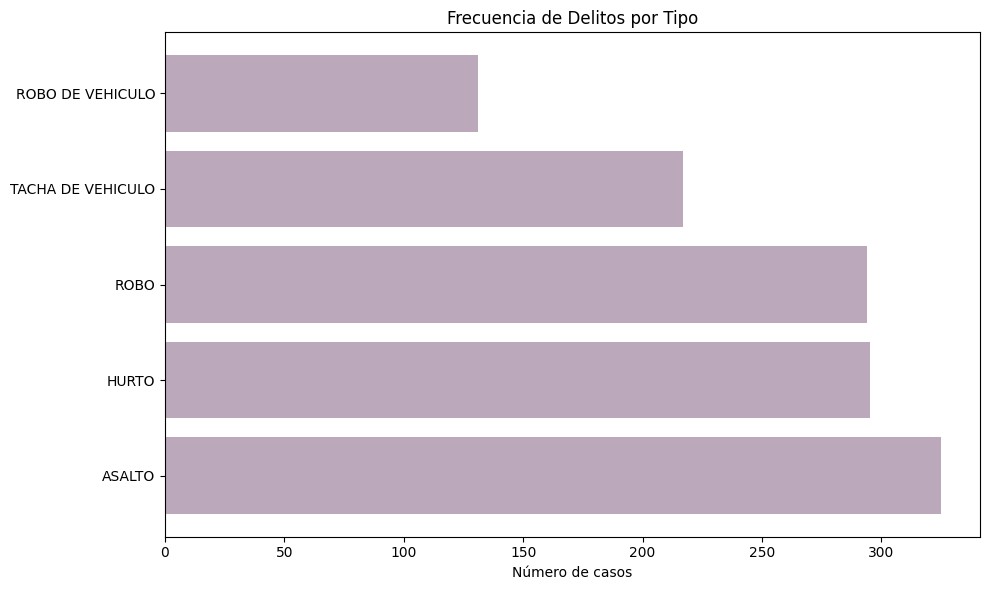

In [44]:
df_pd = Tabla3.toPandas()

plt.figure(figsize=(10, 6))
plt.barh(df_pd['tipo_delito'], df_pd['frecuencia_delitos'], color='#BBA9BB')
plt.title('Frecuencia de Delitos por Tipo')
plt.xlabel('Número de casos')
plt.tight_layout()
plt.show()

#### Descripción:
Esta visualización muestra los tipos de delitos más frecuentes en el distrito con mayor número de incidentes registrados según los datos del `OIJ`. Primero, se identificó ese distrito mediante una subconsulta con `RANK()` y se filtraron los delitos cometidos en él. Luego, se agruparon por tipo y se contó la cantidad de casos. Con `Matplotlib` se generó un gráfico de barras horizontales para representar la frecuencia de cada tipo de delito. Este tipo de visualización facilita comparar visualmente cuáles delitos son más comunes en la zona con mayor incidencia.

- ### Visualización 4:
Gráfica de la cantidad de delitos por sexo para todo el conjunto de datos.

In [45]:
visualizacion= """
SELECT 
    "Sexo", 
    COUNT(*) AS cantidad_delitos
FROM 
    DATOSOIJ
GROUP BY 
    "Sexo"
ORDER BY 
    cantidad_delitos DESC
"""
Tabla4 = spark.read \
    .format("jdbc") \
    .option("url", POSTGRESQL_URL) \
    .option("dbtable", f"({visualizacion}) AS subquery") \
    .option("user", POSTGRESQL_USER) \
    .option("password", POSTGRESQL_PASSWORD) \
    .load()

Tabla4.show()

+-----------+----------------+
|       Sexo|cantidad_delitos|
+-----------+----------------+
|     HOMBRE|           33773|
|      MUJER|           13445|
|DESCONOCIDO|             262|
+-----------+----------------+



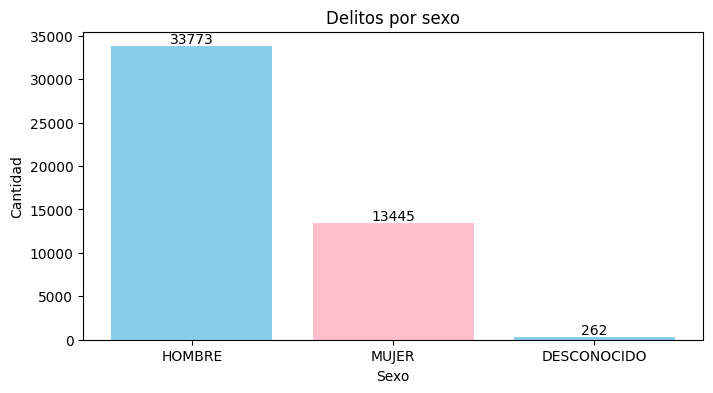

In [46]:
df_pd = Tabla4.toPandas()

plt.figure(figsize=(8, 4))
plt.bar(df_pd['Sexo'], df_pd['cantidad_delitos'], color=['skyblue', 'pink'])

plt.title('Delitos por sexo')
plt.xlabel('Sexo')
plt.ylabel('Cantidad')

# Mostrar valores en las barras
for i, v in enumerate(df_pd['cantidad_delitos']):
    plt.text(i, v, str(v), ha='center', va='bottom')

plt.show()

#### Descripción:
Esta visualización presenta la cantidad de delitos registrados según el sexo de las personas involucradas, utilizando los datos del `OIJ`. Se agrupan los registros por la columna ***"Sexo"*** y cuentan la cantidad total de casos por cada categoría. Con `Matplotlib` se construyó un gráfico de barras donde se diferencian los valores por color (celeste y rosado), y se añadieron etiquetas numéricas encima de cada barra para facilitar la lectura. Esta visualización permite observar rápidamente la distribución de delitos según el sexo.

- ### Visualización 5:
Propuesta de una visualización de nuestro interés. Esta trata sobre las nacionalidades que más realizan delitos a nivel de Costa Rica en el  año 2011.   

In [47]:
visualizacion = """
SELECT 
    "Nacionalidad" AS nacionalidad,
    COUNT(*) AS total_delitos
FROM 
    DATOSOIJ
WHERE 
    "Nacionalidad" IS NOT NULL
GROUP BY 
    "Nacionalidad"
ORDER BY 
    total_delitos DESC
LIMIT 5
"""
Tabla5 = spark.read \
    .format("jdbc") \
    .option("url", POSTGRESQL_URL) \
    .option("dbtable", f"({visualizacion}) AS subquery") \
    .option("user", POSTGRESQL_USER) \
    .option("password", POSTGRESQL_PASSWORD) \
    .load()

Tabla5.show()


+--------------+-------------+
|  nacionalidad|total_delitos|
+--------------+-------------+
|    COSTA RICA|        39519|
|     NICARAGUA|         2795|
|   Desconocido|         1124|
|ESTADOS UNIDOS|         1077|
|      COLOMBIA|          332|
+--------------+-------------+



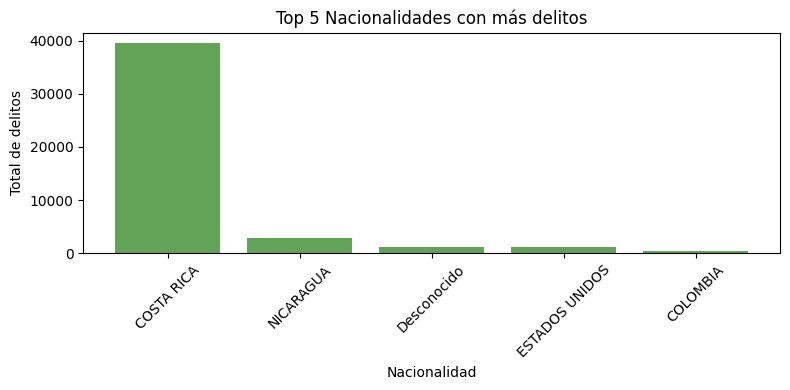

In [48]:
df_pd = Tabla5.toPandas()

# Crear gráfico básico
plt.figure(figsize=(8, 4))
plt.bar(df_pd['nacionalidad'], df_pd['total_delitos'], color='#63A355')

# Títulos y etiquetas
plt.title('Top 5 Nacionalidades con más delitos')
plt.xlabel('Nacionalidad')
plt.ylabel('Total de delitos')

# Rotar etiquetas del eje X para mejor lectura
plt.xticks(rotation=45)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

#### Descripción:
Esta visualización muestra las cinco nacionalidades con mayor cantidad de delitos registrados en los datos del `OIJ`. Se filtra los registros con nacionalidad no nula, se agrupa por nacionalidad y se selecciona las cinco con más casos. Luego con `Matplotlib` se generó un gráfico de barras que permite comparar visualmente el total de delitos asociados a cada nacionalidad.

## Conclusiones respecto a los datos analizados
- **Relación entre ocupación y criminalidad:** Al comparar la cantidad de delitos con la tasa de ocupación en los distritos más afectados, se observa que algunos de estos presentan tasas de ocupación moderadas o bajas. Esto podría indicar una posible relación entre el desempleo y la incidencia delictiva.
- **Los días con más delitos:** La actividad delictiva no es igual todos los días, hay días de la semana en los que los crímenes aumentan. Esta información podría ser clave para que las autoridades optimicen el patrullaje y los operativos en los momentos de mayor riesgo.
- **Diferencias de género:**  El análisis por sexo muestra una diferencia considerable en la cantidad de delitos entre hombres y mujeres, lo cual podría estar relacionado con roles sociales. Esto puede orientar futuras investigaciones sobre el género y la criminalidad.
- **Delitos que más se repiten:** En las zonas con mayor criminalidad, no todos los delitos ocurren con la misma frecuencia. Identificar estos patrones permitiría a las autoridades tomar medidas más efectivas, atacando primero los problemas más recurrentes.

## Referencias bibliográficas:
- Matplotlib cheatsheets — Visualization with Python. (s. f.). https://matplotlib.org/cheatsheets/
- Lau, K. (2022, 7 mayo). Multiple SparkContext instances error when launching PYSPARK. Medium. https://medium.com/@madtopcoder/multiple-sparkcontext-instances-error-when-launching-pyspark-644e7a94e40f
- pyspark.sql.DataFrame.join — PySpark 4.0.0 documentation. (s. f.). https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.join.html
- Think And Build. (2020, 22 mayo). Data Visualization using Python on Jupyter Notebook [Vídeo]. YouTube. https://www.youtube.com/watch?v=tse_8LLWtfY